# Benchmark Results — mixed-second-price-exponential-eta50

Robustness study notebook for the **mixed kernel, second-price, exponential competition, exponential horizon η=50**.
It compares three RL algorithms (**PPO**, **SAC**, **TD3**) and a set of
planning baselines (**FiPla**, **GreedyMyopic**, **Shading**, **MPC** variants)
on the `mixed-second-price-exponential-eta50` scenario.

## How to run this notebook

1. Set `SWEEP_CSV` to the path of the shading-sweep CSV produced by `run_shading_sweep_robustness.sh`.
2. Set `RESULTS_CSV` to the path of the main evaluation CSV produced by `run_evaluate_robustness.sh`.
3. Run all cells.


In [1]:
import sys, pathlib, os
# Notebook lives in benchmark/notebooks/; find repo root robustly
try:
    # VS Code sets __vsc_ipynb_file__ to the notebook's absolute path
    _nb_dir = pathlib.Path(__vsc_ipynb_file__).parent
except NameError:
    # Classic Jupyter: CWD is the notebook directory
    _nb_dir = pathlib.Path().resolve()
repo_root = _nb_dir.parent.parent  # notebooks/ -> benchmark/ -> repo root
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))
os.chdir(repo_root)

In [2]:
%matplotlib inline
from benchmark.evaluate import score_matrix
from benchmark import plots
import pandas as pd
import glob
import matplotlib.pyplot as plt
import os
import numpy as np
import seaborn as sns

## Configuration

Set the paths to the sweep and main results CSVs below.
Leave as `None` to auto-detect from the most recent matching files.

In [3]:
SCENARIO_ID = "mixed-second-price-exponential-eta50"

# Path to the shading alpha sweep CSV (produced by run_shading_sweep_robustness.sh)
# If None, auto-detected as the most recent CSV where ALL policies are Shading variants.
SWEEP_CSV = None  # e.g. "benchmark/benchmark_results/rebuttal/mixed-second-price-exponential-eta50_eta50_2026-07-25_12-00-00.csv"

# Path to ONE specific results CSV, or None to auto-merge ALL non-sweep CSVs.
# Auto-merge is the normal mode: each eval job (baselines, mpc, shading, rl) produces
# its own CSV; the notebook concatenates them all automatically.
RESULTS_CSV = None

## Shading α sweep

Grid search over the shading multiplier α. We report mean episode reward per α and pick the best.

In [4]:
# Auto-detect: find most recent CSV for this scenario where all policies are Shading
_all_csvs = sorted(glob.glob(f"benchmark/benchmark_results/rebuttal/mixed-second-price-exponential-eta50_*.csv"))

if SWEEP_CSV is not None:
    sweep_df = pd.read_csv(SWEEP_CSV)
    print(f"Loaded sweep: {SWEEP_CSV}")
elif _all_csvs:
    # Pick file where the only policies are Shading variants
    sweep_df = None
    for _f in reversed(_all_csvs):
        _tmp = pd.read_csv(_f)
        if all(_p.startswith("Shading") for _p in _tmp["policy"].unique()):
            sweep_df = _tmp
            print(f"Auto-detected sweep CSV: {_f}")
            break
    if sweep_df is None:
        raise FileNotFoundError("No shading-only CSV found. Set SWEEP_CSV manually.")
else:
    raise FileNotFoundError(
        f"No CSVs found for scenario {SCENARIO_ID}. "
        "Run run_shading_sweep_robustness.sh first."
    )

shading_summary = (
    sweep_df.sort_values(["policy", "seed", "step"])
    .groupby(["policy", "seed"])["cum_reward"].last()
    .reset_index()
    .rename(columns={"cum_reward": "episode_reward"})
)
# Extract numeric alpha from policy name "Shading(α=X)"
shading_summary["α"] = (
    shading_summary["policy"]
    .str.extract(r"α=([0-9.]+)")[0]
    .astype(float)
)
shading_summary.head()

Auto-detected sweep CSV: benchmark/benchmark_results/rebuttal/mixed-second-price-exponential-eta50_etadefault_2026-07-25_09-55-02.csv


,policy,seed,episode_reward,α
0,Shading(α=0.25),0,0.000000,0.25
1,Shading(α=0.25),1,9.092123,0.25
2,Shading(α=0.25),2,0.740523,0.25
3,Shading(α=0.25),3,-0.240757,0.25
4,Shading(α=0.25),4,-0.074422,0.25


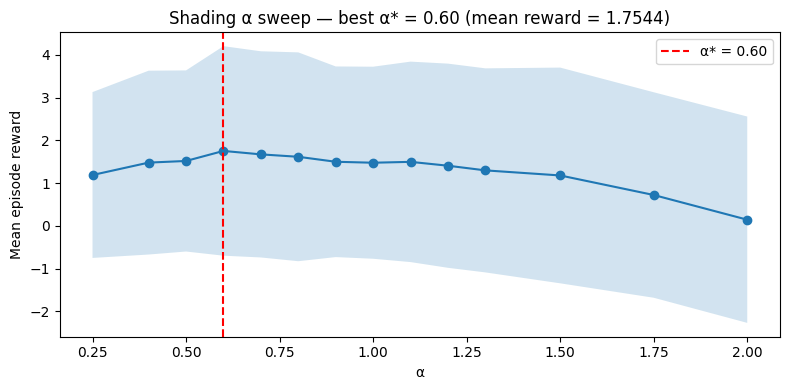

Best alpha: 0.6  (mean reward = 1.7544)


In [5]:
mean_r = shading_summary.groupby("α")["episode_reward"].mean()
std_r  = shading_summary.groupby("α")["episode_reward"].std()
best_alpha = mean_r.idxmax()
best_reward = mean_r.loc[best_alpha]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(mean_r.index, mean_r.values, marker="o")
ax.fill_between(mean_r.index, mean_r - std_r, mean_r + std_r, alpha=0.2)
ax.axvline(best_alpha, color="red", linestyle="--", label=f"α* = {best_alpha:.2f}")
ax.set_xlabel("α")
ax.set_ylabel("Mean episode reward")
ax.set_title(f"Shading α sweep — best α* = {best_alpha:.2f} (mean reward = {best_reward:.4f})")
ax.legend()
plt.tight_layout()
plt.show()
print(f"Best alpha: {best_alpha}  (mean reward = {best_reward:.4f})")

/tmp/ipykernel_13354/1030916121.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f"{a:.2f}" for a in alphas_sorted], rotation=45, ha="right")


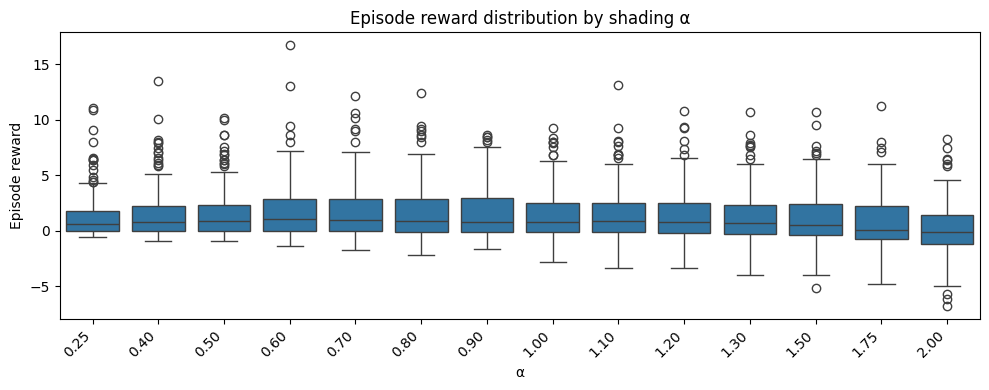

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
alphas_sorted = sorted(shading_summary["α"].unique())
sns.boxplot(data=shading_summary, x="α", y="episode_reward", order=alphas_sorted, ax=ax)
ax.set_xticklabels([f"{a:.2f}" for a in alphas_sorted], rotation=45, ha="right")
ax.set_xlabel("α")
ax.set_ylabel("Episode reward")
ax.set_title("Episode reward distribution by shading α")
plt.tight_layout()
plt.show()

## 1. Load main results

Each evaluation job (baselines, MPC, shading, RL) produces its own CSV. All non-sweep CSVs for this scenario are concatenated into a single dataframe.

Set `RESULTS_CSVS` to a list of specific paths to override auto-detection.

In [ ]:
if RESULTS_CSV is not None:
    # Single explicit path (legacy)
    _result_parts = [pd.read_csv(RESULTS_CSV)]
    print(f"Loaded results: {RESULTS_CSV}")
elif _all_csvs:
    # Concatenate ALL CSVs that are not pure shading-sweep files
    _result_parts = []
    for _f in _all_csvs:
        _tmp = pd.read_csv(_f)
        if not all(_p.startswith("Shading") for _p in _tmp["policy"].unique()):
            _result_parts.append(_tmp)
            print(f"Adding results CSV: {_f}")
    if not _result_parts:
        raise FileNotFoundError(
            "No non-sweep CSVs found. Run run_eval_baselines_robustness.sh / "
            "run_eval_mpc_robustness.sh / run_eval_rl_robustness.sh first."
        )
else:
    raise FileNotFoundError(
        f"No CSVs found for {SCENARIO_ID}. Run the evaluation scripts first."
    )

df = pd.concat(_result_parts, ignore_index=True)
print(f"\nPolicies: {list(df['policy'].unique())}")
print(f"Seeds: {df['seed'].nunique()}")

Adding results CSV: benchmark/benchmark_results/rebuttal/mixed-second-price-exponential-eta50_etadefault_2026-07-24_21-51-32.csv

Policies: ['FiPla', 'GreedyMyopic']
Seeds: 1000


In [8]:
scores = score_matrix(df)

In [9]:
algos_list = df["policy"].unique()
algos_list

<StringArray>
['FiPla', 'GreedyMyopic']
Length: 2, dtype: str

## 2. Plots

### Aggregate metrics

IQM, mean, median, and optimality gap of episode reward across seeds, with stratified bootstrap confidence intervals (rliable).

  Saved -> /home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots/aggregate_metrics_mixed_eta50.pdf


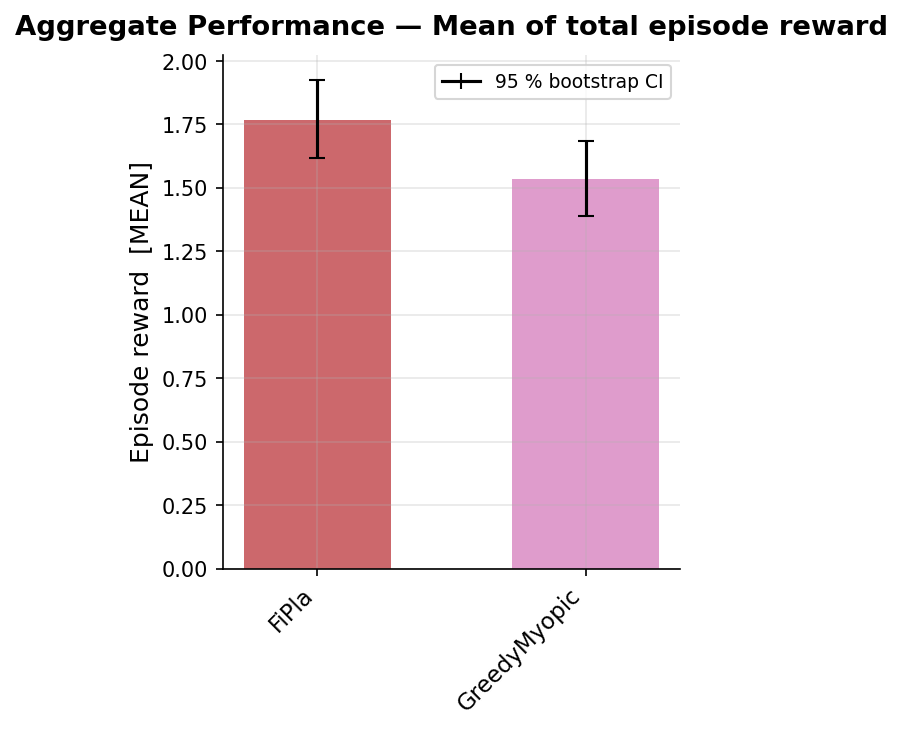

In [10]:
_ = plots.plot_aggregate_metrics(scores, metric="mean", normalize_by=None, filename="aggregate_metrics_mixed_eta50.pdf")

### Performance profiles

Fraction of seeds on which each policy achieves at least a given score threshold τ. A curve that is higher and further to the right indicates more consistent performance.

In [ ]:
_ = plots.plot_performance_profiles(scores, filename="performance_profiles_mixed_eta50.pdf")

### Cumulative reward over time

Mean cumulative reward as a function of **normalised campaign time** (each episode’s time axis is rescaled to [0, 1] before averaging), across all seeds. Shaded bands show ±1 standard deviation.

In [ ]:
_ = plots.plot_cumulative_reward(df, filename="cumulative_reward_mixed_eta50.pdf")

### Episode reward distribution

Distribution of total episode reward across seeds for each policy.

In [ ]:
_ = plots.plot_reward_distribution(df, filename="reward_distribution_mixed_eta50.pdf")

### Context dynamics

Evolution of the context signal `ctx` and the expected reward over **normalised campaign time** (rescaled to [0, 1] per seed), averaged across all seeds. The context signal `ctx` encodes the cumulative saturation of the advertising slot.

In [ ]:
_ = plots.plot_context_dynamics(df, filename="context_dynamics_mixed_eta50.pdf")

### Bid distributions

Distribution of submitted bids across all steps and seeds for each policy, overlaid with the expected value signal (`expected_reward`).

In [ ]:
_ = plots.plot_bid_distributions(df, filename="bid_distributions_mixed_eta50.pdf")

### Win rate

Fraction of auctions won per policy, averaged over seeds.

In [ ]:
_ = plots.plot_win_rate(df, filename="win_rate_mixed_eta50.pdf")

### MPC’s optimal alphas

At each auction step, MPC-family policies select the shading multiplier α* that maximises the estimated planning return over a rolling horizon. The distribution shows which α* values are preferred across all steps and seeds.

In [ ]:
_ = plots.plot_mpc_alpha_chosen(df, filename="mpc_alpha_chosen_mixed_eta50.pdf")

### MPC chosen α* over normalised campaign time

Time is normalised to [0, 1] for each run before averaging. The curves show how the preferred shading multiplier evolves from the start to the end of a campaign.

In [ ]:
_ = plots.plot_alpha_over_normalized_time(df, filename="mpc_alpha_over_time_mixed_eta50.pdf")